In [1]:
pip install opencv-python numpy matplotlib

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

     -------------------                      20.4/41.2 MB 3.9 MB/s eta 0:00:06


ERROR: Exception:
Traceback (most recent call last):
  File "C:\ProgramData\anaconda3\lib\site-packages\pip\_vendor\urllib3\response.py", line 437, in _error_catcher
    yield
  File "C:\ProgramData\anaconda3\lib\site-packages\pip\_vendor\urllib3\response.py", line 560, in read
    data = self._fp_read(amt) if not fp_closed else b""
  File "C:\ProgramData\anaconda3\lib\site-packages\pip\_vendor\urllib3\response.py", line 526, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
  File "C:\ProgramData\anaconda3\lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 90, in read
    data = self.__fp.read(amt)
  File "C:\ProgramData\anaconda3\lib\http\client.py", line 465, in read
    s = self.fp.read(amt)
  File "C:\ProgramData\anaconda3\lib\socket.py", line 705, in readinto
    return self._sock.recv_into(b)
  File "C:\ProgramData\anaconda3\lib\ssl.py", line 1274, in recv_into
    return self.read(nbytes, buffer)
  File "C:\ProgramData\anaconda3\lib

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [3]:
# Read the image using OpenCV
img = cv2.imread('road.jpg')

# OpenCV loads images as BGR, so convert to RGB for correct display in matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image shape:", img.shape)

Image shape: (960, 640, 3)


In [4]:
# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

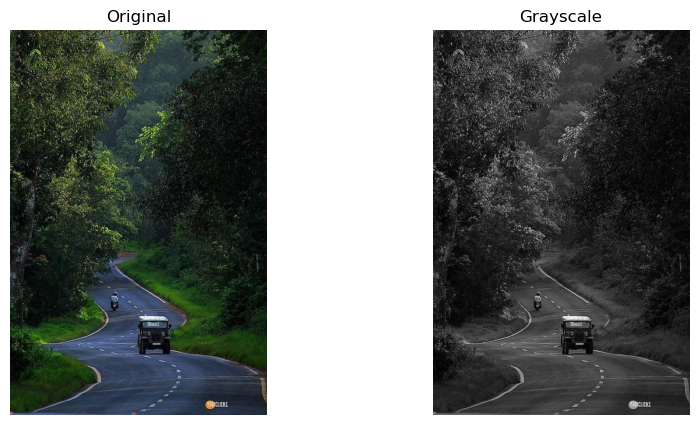

In [5]:
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale")
plt.axis('off')

plt.show()

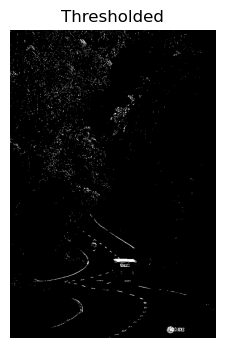

In [6]:
# Apply thresholding
threshold = 150
_, thresh = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(6,4))
plt.imshow(thresh, cmap='gray')
plt.title("Thresholded")
plt.axis('off')
plt.show()

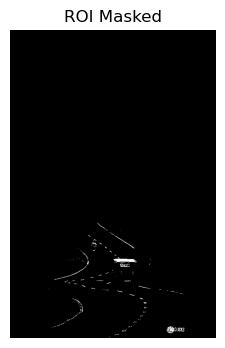

In [7]:
# ROI masking (do not modify)
height, width = thresh.shape
polygon = np.array([[
    (0, height),
    (int(width * 0.45), int(height * 0.6)),
    (int(width * 0.55), int(height * 0.6)),
    (width, height)
]], dtype=np.int32)

mask = np.zeros_like(thresh)
cv2.fillPoly(mask, polygon, 255)
roi = cv2.bitwise_and(thresh, mask)

plt.figure(figsize=(6,4))
plt.imshow(roi, cmap='gray')
plt.title("ROI Masked")
plt.axis('off')
plt.show()

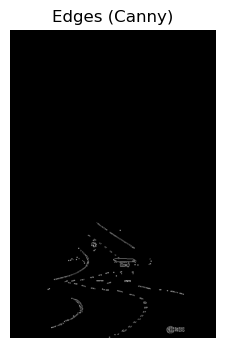

In [8]:
# Perform Edge Detection
edges = cv2.Canny(roi, 50, 150)

plt.figure(figsize=(6,4))
plt.imshow(edges, cmap='gray')
plt.title("Edges (Canny)")
plt.axis('off')
plt.show()

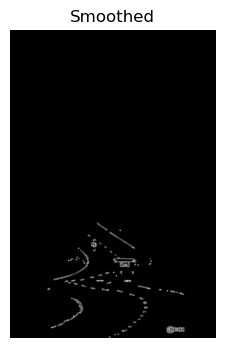

In [9]:
# Apply Gaussian Blur to smooth the edge image
blurred = cv2.GaussianBlur(edges, (5, 5), 0)

plt.figure(figsize=(6,4))
plt.imshow(blurred, cmap='gray')
plt.title("Smoothed")
plt.axis('off')
plt.show()

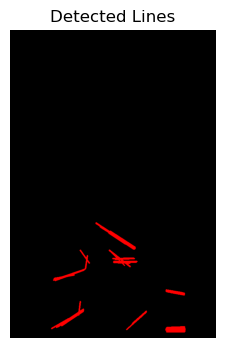

In [10]:
# Detect lines using Hough Transform (probabilistic version)
lines = cv2.HoughLinesP(
    blurred,
    rho=2,
    theta=np.pi / 180,
    threshold=50,
    minLineLength=40,
    maxLineGap=5
)

# Draw the raw detected lines on a blank image
line_img = np.zeros_like(img)
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.reshape(4)
        cv2.line(line_img, (x1, y1), (x2, y2), (0, 0, 255), 3)

plt.figure(figsize=(6,4))
plt.imshow(cv2.cvtColor(line_img, cv2.COLOR_BGR2RGB))
plt.title("Detected Lines")
plt.axis('off')
plt.show()

In [11]:
# Lane detection logic (do not modify)
def make_coordinates(image, line_params):
    slope, intercept = line_params
    y1 = image.shape[0]
    y2 = int(y1 * 0.6)
    x1 = int((y1 - intercept) / slope)
    x2 = int((y2 - intercept) / slope)
    return np.array([x1, y1, x2, y2])

def average_lanes(image, lines):
    left_fit, right_fit = [], []
    if lines is None:
        return None
    for line in lines:
        x1, y1, x2, y2 = line.reshape(4)
        if x1 == x2:
            continue
        slope, intercept = np.polyfit((x1, x2), (y1, y2), 1)
        if slope < -0.3:
            left_fit.append((slope, intercept))
        elif slope > 0.3:
            right_fit.append((slope, intercept))

    lanes = []
    if left_fit:
        lanes.append(make_coordinates(image, np.average(left_fit, axis=0)))
    if right_fit:
        lanes.append(make_coordinates(image, np.average(right_fit, axis=0)))
    return np.array(lanes)

lanes = average_lanes(img, lines)

lane_img = np.zeros_like(img)
if lanes is not None:
    for x1, y1, x2, y2 in lanes:
        cv2.line(lane_img, (x1, y1), (x2, y2), (0, 255, 0), 10)

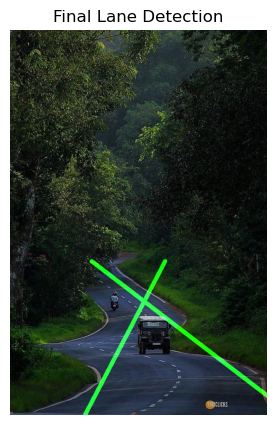

In [12]:
# Combine the lane lines with the original image
final = cv2.addWeighted(img, 0.8, lane_img, 1, 0)

plt.figure(figsize=(10,5))
plt.imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB))
plt.title("Final Lane Detection")
plt.axis('off')
plt.show()